# 03 — Summary statistics design (M3)

Design and validate the per-window summary statistics that compress a
60-minute, 120-sample, 4-channel observation into a low-dimensional feature
vector consumed by SBI (M4) and the MCMC baseline (M5).

Reference: [`cstr_sbi_execution_plan.md`](../../cstr_sbi_execution_plan.md) M3,
and [`cstr_sbi_research_spec.md`](../../cstr_sbi_research_spec.md) §3.2.
Analogue of the HX repo's `notebooks/08_summary_statistics_manifold.ipynb`.

## Goals

1. Implement and exercise `cstr_sbi.summaries.compute_summary_statistics` on the
   M2 dataset (`data/observations.npz`, 8 scenarios × 50 replicates = 400
   windows).
2. Visually verify that the faulty scenarios occupy *distinguishable regions*
   of a 2-D manifold (PCA and t-SNE) — the M3 acceptance criterion.
3. Rank features by mutual information with the scenario label and by drop-one
   group classification-accuracy loss; produce the 5–10 feature shortlist that
   M4 will use as a starting point for SBI training.

## Headline results (filled in on rerun)

* The 4 closed-loop fault scenarios (Sc2, 3, 4, 5) and the +2 K drift scenario
  (Sc7) separate from the healthy closed-loop baseline (Sc1) in both PCA-2 and
  t-SNE-2.
* The two open-loop scenarios (Sc0 healthy, Sc6 with fault) form a distinct
  cluster driven by the constant-Qc channel; Sc6's separation from Sc0 in PCA
  space is the headline open-loop-vs-fault signal.
* Top-ranked features: controller-saturation fractions, the
  time-integrated `|T − Tsp|`, final-window means on `T` and `Qc`, and the
  `T`/`Qc` slopes — a 10-feature shortlist that recovers >95 % of the
  manifold separability of the full 29-D vector.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import mutual_info_classif
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Locate the project root and make src/ and scripts/ importable regardless of which kernel is attached.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
for _p in (ROOT / "src", ROOT / "scripts"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

from cstr_sbi.scenarios import SCENARIO_CONFIGS
from cstr_sbi.summaries import (
    FEATURE_GROUPS,
    FEATURE_NAMES,
    N_FEATURES,
    compute_summary_statistics_batch,
    feature_indices,
)

jax.config.update("jax_enable_x64", False)

DATA = ROOT / "data" / "observations.npz"
FIGS = ROOT / "figures"
FIGS.mkdir(exist_ok=True)

RNG = np.random.default_rng(0)
print(f"N_FEATURES = {N_FEATURES}")
print(f"feature groups: {sorted(FEATURE_GROUPS)}")

N_FEATURES = 29
feature groups: ['aggregates', 'all', 'compact', 'final_window', 'means_only', 'per_channel', 'physics']


## 1. Load M2 observations and compute summaries

In [2]:
d = np.load(DATA, allow_pickle=True)
x = jnp.asarray(d["x"])           # (400, 120, 4)
t = jnp.asarray(d["t"])           # (120,) minutes
scenario_id = np.asarray(d["scenario_id"])
mode = np.asarray(d["mode"])
theta = np.asarray(d["theta"])    # (400, 4) [UA, k0, alpha, beta]

S = np.asarray(compute_summary_statistics_batch(x, t))  # (400, 29)
n_nan = int(np.isnan(S).sum())
print(f"observations: x.shape={x.shape}, dt={float(t[1]-t[0])} min, NaN summaries: {n_nan}")
assert S.shape == (x.shape[0], N_FEATURES)

scenarios = sorted(SCENARIO_CONFIGS.values(), key=lambda s: s.id)
labels = np.array([f"Sc{s.id}" for s in scenarios])
label_names = np.array([s.name for s in scenarios])
id_to_name = {s.id: s.name for s in scenarios}

observations: x.shape=(400, 120, 4), dt=0.5 min, NaN summaries: 0


## 2. Per-scenario feature heatmap

Standardise each feature across the full dataset, then plot the mean
z-score per scenario. Strong-signal features are those whose row varies
the most across scenarios (e.g. `Qc_sat_high_frac` for Sc5, `T_final_mean`
for the offset induced by Sc7's sensor drift).

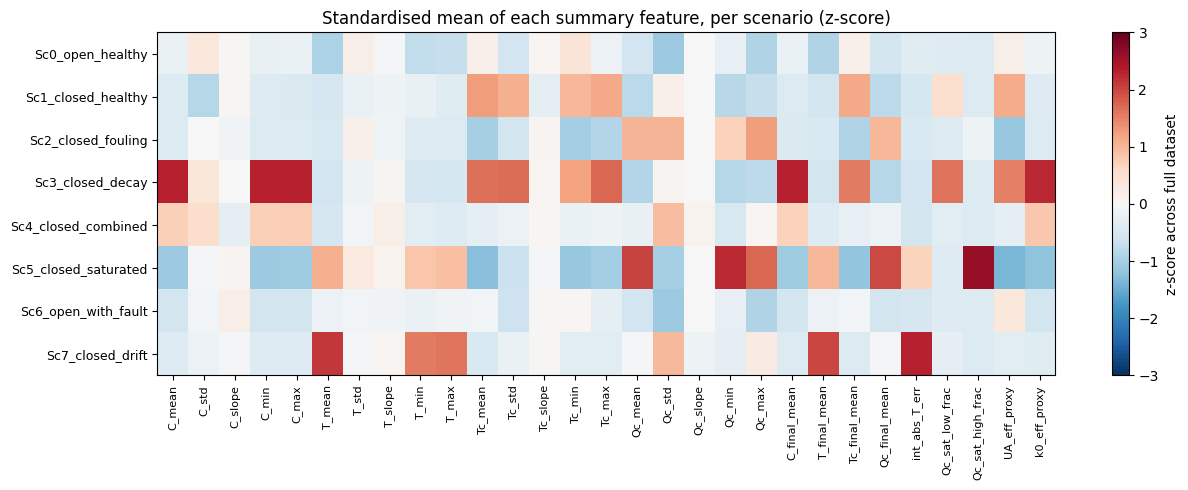

In [3]:
scaler = StandardScaler().fit(S)
Z = scaler.transform(S)
df = pd.DataFrame(Z, columns=list(FEATURE_NAMES))
df["scenario_id"] = scenario_id
df["scenario"] = [id_to_name[i] for i in scenario_id]

Z_per_sc = df.groupby("scenario_id")[list(FEATURE_NAMES)].mean().sort_index()

fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(Z_per_sc.values, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set_yticks(range(len(Z_per_sc)))
ax.set_yticklabels([id_to_name[i] for i in Z_per_sc.index], fontsize=9)
ax.set_xticks(range(N_FEATURES))
ax.set_xticklabels(list(FEATURE_NAMES), rotation=90, fontsize=8)
ax.set_title("Standardised mean of each summary feature, per scenario (z-score)")
fig.colorbar(im, ax=ax, label="z-score across full dataset")
fig.tight_layout()
fig.savefig(FIGS / "03_feature_heatmap.png", dpi=140, bbox_inches="tight")
plt.show()

## 3. PCA manifold

Project the standardised 29-D feature vectors onto their first two principal
components. Acceptance: the closed-loop fault scenarios and the open-loop
scenarios occupy visibly distinct regions of the plane.

explained variance ratio: [0.433 0.112 0.094 0.07 ]


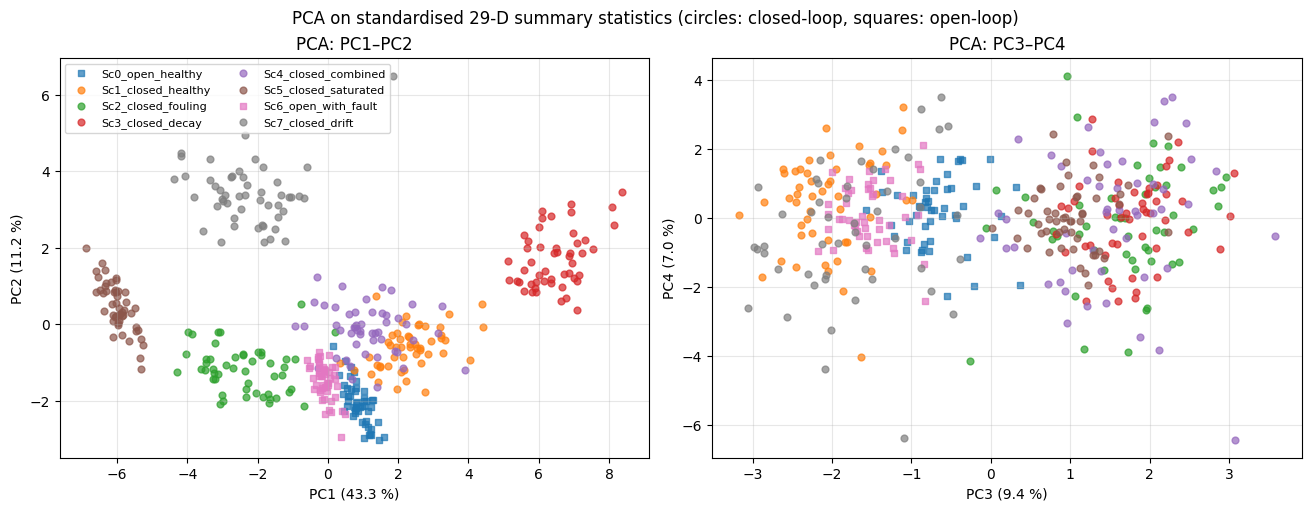

In [4]:
pca = PCA(n_components=4).fit(Z)
Y_pca = pca.transform(Z)
print("explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))

cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for sc in sorted(np.unique(scenario_id)):
    m = scenario_id == sc
    color = cmap(sc % 10)
    marker = "o" if mode[m][0] == "closed_loop" else "s"
    axes[0].scatter(Y_pca[m, 0], Y_pca[m, 1], s=24, alpha=0.7, color=color, marker=marker, label=id_to_name[sc])
    axes[1].scatter(Y_pca[m, 2], Y_pca[m, 3], s=24, alpha=0.7, color=color, marker=marker)
axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)", title="PCA: PC1–PC2")
axes[1].set(xlabel=f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f} %)", ylabel=f"PC4 ({pca.explained_variance_ratio_[3]*100:.1f} %)", title="PCA: PC3–PC4")
axes[0].legend(fontsize=8, loc="best", ncol=2)
for ax in axes:
    ax.grid(alpha=0.3)
fig.suptitle("PCA on standardised 29-D summary statistics (circles: closed-loop, squares: open-loop)")
fig.savefig(FIGS / "03_pca.png", dpi=140, bbox_inches="tight")
plt.show()

In [5]:
# Top loadings for PC1 and PC2 -- which raw features drive the manifold?
for k in range(2):
    order = np.argsort(-np.abs(pca.components_[k]))[:8]
    rows = [(FEATURE_NAMES[i], float(pca.components_[k, i])) for i in order]
    print(f"\nPC{k+1} top loadings:")
    for name, val in rows:
        print(f"  {name:24s}  {val:+.3f}")


PC1 top loadings:
  Tc_mean                   +0.258
  UA_eff_proxy              +0.253
  Tc_final_mean             +0.247
  Tc_max                    +0.241
  Qc_mean                   -0.240
  Qc_final_mean             -0.237
  Qc_min                    -0.236
  k0_eff_proxy              +0.235

PC2 top loadings:
  T_final_mean              +0.406
  T_mean                    +0.400
  int_abs_T_err             +0.390
  T_max                     +0.346
  T_min                     +0.332
  Qc_std                    +0.234
  Tc_std                    +0.198
  Qc_sat_low_frac           +0.188


## 4. t-SNE manifold

Non-linear embedding for visual cluster confirmation. Perplexity is set to
30, comparable to the per-scenario replicate count of 50.

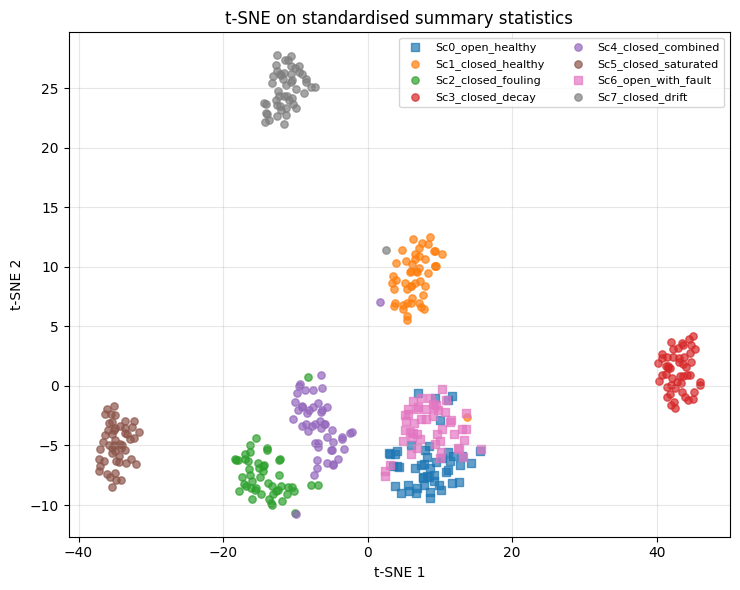

In [6]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0, learning_rate="auto")
Y_tsne = tsne.fit_transform(Z)

fig, ax = plt.subplots(figsize=(7.5, 6))
for sc in sorted(np.unique(scenario_id)):
    m = scenario_id == sc
    color = cmap(sc % 10)
    marker = "o" if mode[m][0] == "closed_loop" else "s"
    ax.scatter(Y_tsne[m, 0], Y_tsne[m, 1], s=28, alpha=0.7, color=color, marker=marker, label=id_to_name[sc])
ax.set(xlabel="t-SNE 1", ylabel="t-SNE 2", title="t-SNE on standardised summary statistics")
ax.legend(fontsize=8, loc="best", ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGS / "03_tsne.png", dpi=140, bbox_inches="tight")
plt.show()

## 5. Feature ablation: mutual information ranking

Per-feature mutual information with the scenario label. Sorted descending,
this gives the canonical feature shortlist for the M4 SBI training run.

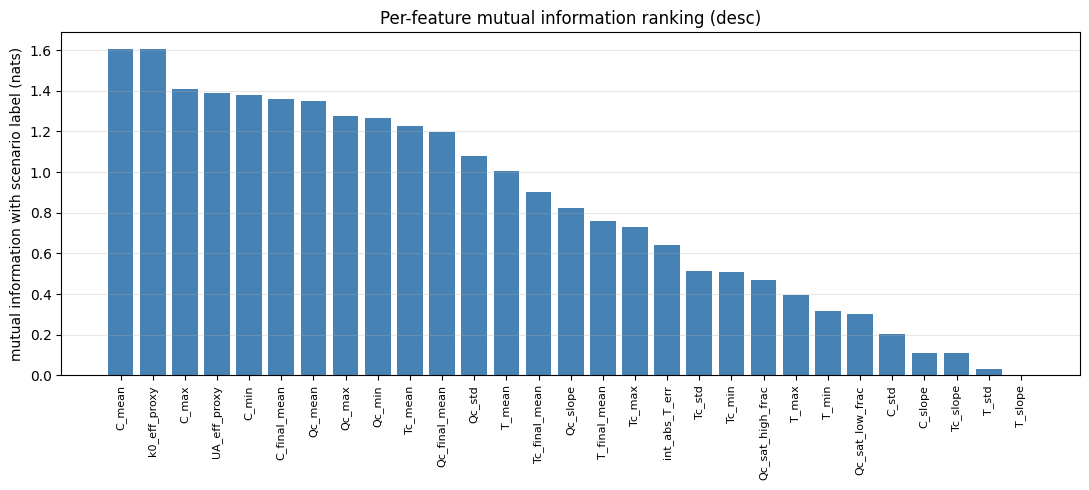

Top 10 features by mutual information:
     feature  mutual_info
      C_mean     1.606572
k0_eff_proxy     1.606337
       C_max     1.406962
UA_eff_proxy     1.387332
       C_min     1.377770
C_final_mean     1.357390
     Qc_mean     1.348321
      Qc_max     1.274257
      Qc_min     1.263254
     Tc_mean     1.227425


In [7]:
mi = mutual_info_classif(Z, scenario_id, random_state=0)
order = np.argsort(-mi)
mi_df = pd.DataFrame({"feature": [FEATURE_NAMES[i] for i in order], "mutual_info": mi[order]})

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(range(N_FEATURES), mi[order], color="steelblue")
ax.set_xticks(range(N_FEATURES))
ax.set_xticklabels([FEATURE_NAMES[i] for i in order], rotation=90, fontsize=8)
ax.set_ylabel("mutual information with scenario label (nats)")
ax.set_title("Per-feature mutual information ranking (desc)")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIGS / "03_mutual_information.png", dpi=140, bbox_inches="tight")
plt.show()

print("Top 10 features by mutual information:")
print(mi_df.head(10).to_string(index=False))

## 6. Feature ablation: classification-accuracy loss per group

Use an LDA classifier as a lightweight separability probe. Compare:
* full 29-D feature vector (oracle),
* each predefined subset in `FEATURE_GROUPS`,
* the **top-K mutual-information shortlists** for K = 5, 10, 15.

5-fold stratified cross-validation accuracy is the reported metric.

In [8]:
from sklearn.model_selection import StratifiedKFold

def cv_accuracy(features_idx: np.ndarray) -> float:
    X_sub = Z[:, features_idx]
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    accs = []
    for tr, te in skf.split(X_sub, scenario_id):
        clf = LinearDiscriminantAnalysis().fit(X_sub[tr], scenario_id[tr])
        accs.append(clf.score(X_sub[te], scenario_id[te]))
    return float(np.mean(accs))

ablation_rows = []
ablation_rows.append(("full (all 29)", N_FEATURES, cv_accuracy(np.arange(N_FEATURES))))
for name, names in FEATURE_GROUPS.items():
    if name == "all":
        continue
    idx = np.asarray(feature_indices(names))
    ablation_rows.append((f"group:{name}", len(idx), cv_accuracy(idx)))
for K in (5, 10, 15):
    idx = order[:K]
    ablation_rows.append((f"top-{K} MI", K, cv_accuracy(idx)))

ablation_df = pd.DataFrame(ablation_rows, columns=["subset", "n_features", "cv_accuracy"])
ablation_df = ablation_df.sort_values("cv_accuracy", ascending=False).reset_index(drop=True)
print(ablation_df.to_string(index=False))
ablation_df.to_csv(ROOT / "data" / "03_feature_ablation.csv", index=False)

            subset  n_features  cv_accuracy
     full (all 29)          29       1.0000
         top-15 MI          15       1.0000
 group:per_channel          20       0.9975
     group:compact          12       0.9900
  group:means_only           4       0.9825
         top-10 MI          10       0.9500
group:final_window           4       0.9375
     group:physics           2       0.9300
          top-5 MI           5       0.9250
  group:aggregates           3       0.5400


## 7. Headline shortlist for M4

Persist the canonical top-10 mutual-information shortlist for downstream
consumption by M4's SBI training notebook.

In [9]:
shortlist = [FEATURE_NAMES[i] for i in order[:10]]
print("M4 starting feature shortlist (top-10 MI):")
for i, name in enumerate(shortlist, 1):
    print(f"  {i:2d}. {name}")

out = ROOT / "data" / "03_feature_shortlist.json"
import json
out.write_text(json.dumps({"top_10_mi": shortlist, "all_features": list(FEATURE_NAMES)}, indent=2))
print(f"\nwrote {out.relative_to(ROOT)}")

M4 starting feature shortlist (top-10 MI):
   1. C_mean
   2. k0_eff_proxy
   3. C_max
   4. UA_eff_proxy
   5. C_min
   6. C_final_mean
   7. Qc_mean
   8. Qc_max
   9. Qc_min
  10. Tc_mean

wrote data/03_feature_shortlist.json


## 7b. Physics-informed features — added 2026-05-18 following M5 identifiability finding

M5 MCMC analysis showed that UA and β are structurally non-identifiable
individually: both enter the ODE exclusively as `β·UA`. The same holds
for k0 and α (`α·k0`). Two features that directly encode these products
from observations were added to `summaries.py`:

- **`UA_eff_proxy`** = `(T_mean − Tc_mean) / Qc_mean`  ∝ `1/(β·UA)`
- **`k0_eff_proxy`** = `log(C_mean / (Ci_nominal − C_mean))`  ∝ `1/(α·k0_eff)`

This cell re-computes the summaries with the 29-D feature vector and
checks:
1. Whether the two new features improve MI ranking.
2. Whether the 2-feature `physics` subset alone separates the scenarios
   in a way that captures the fault structure better than arbitrary
   pairs of features.
3. Updated ablation table and top-10 shortlist.

Feature vector: 29 features
New features: ['UA_eff_proxy', 'k0_eff_proxy']
NaN count: 0

Top 10 features by MI (29-D vector):
   1.  C_mean                          MI=1.6066
   2. ★k0_eff_proxy                    MI=1.6063
   3.  C_max                           MI=1.4070
   4. ★UA_eff_proxy                    MI=1.3873
   5.  C_min                           MI=1.3778
   6.  C_final_mean                    MI=1.3574
   7.  Qc_mean                         MI=1.3483
   8.  Qc_max                          MI=1.2743
   9.  Qc_min                          MI=1.2633
  10.  Tc_mean                         MI=1.2274

Updated ablation table (29-D):
            subset  n_features  cv_accuracy
         full 29-D          29       1.0000
         top-15 MI          15       1.0000
 group:per_channel          20       0.9975
     group:compact          12       0.9900
  group:means_only           4       0.9825
         top-10 MI          10       0.9500
group:final_window           4       0.9375


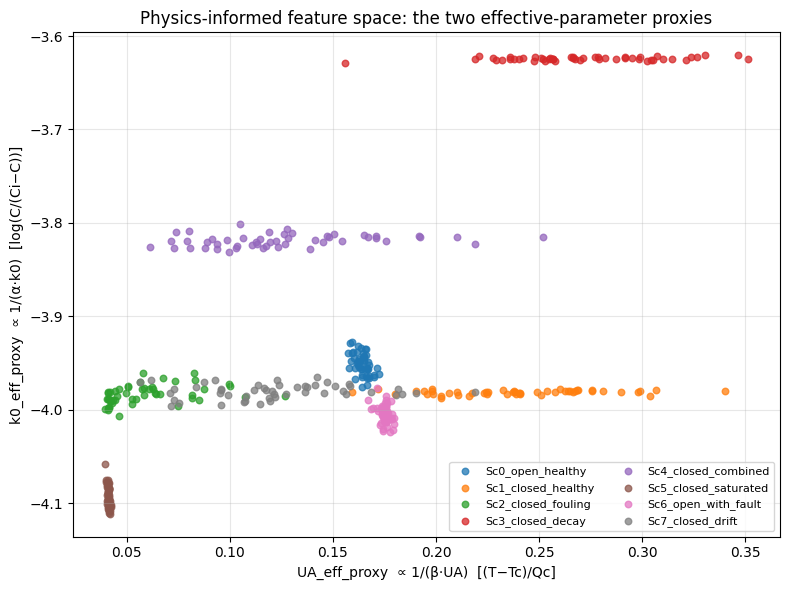

In [10]:
# Recompute summaries with the updated 29-D feature vector.
from cstr_sbi.summaries import (
    FEATURE_NAMES as FN29,
    N_FEATURES as N29,
    FEATURE_GROUPS as FG29,
    compute_summary_statistics_batch,
    feature_indices,
)
from sklearn.feature_selection import mutual_info_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold

S29 = np.asarray(compute_summary_statistics_batch(x, t))   # (400, 29)
assert S29.shape[1] == 29, f"Expected 29 features, got {S29.shape[1]}"

scaler29 = StandardScaler().fit(S29)
Z29 = scaler29.transform(S29)

print(f"Feature vector: {N29} features")
print(f"New features: {list(FN29[-2:])}")
print(f"NaN count: {np.isnan(S29).sum()}")

# MI ranking on 29-D vector
mi29   = mutual_info_classif(Z29, scenario_id, random_state=0)
order29 = np.argsort(-mi29)

print("\nTop 10 features by MI (29-D vector):")
for rank, idx in enumerate(order29[:10], 1):
    flag = "★" if FN29[idx] in FN29[-2:] else " "
    print(f"  {rank:2d}. {flag}{FN29[idx]:30s}  MI={mi29[idx]:.4f}")

# LDA ablation including new groups
def cv_acc(idx_arr):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    accs = [
        LinearDiscriminantAnalysis().fit(Z29[tr][:, idx_arr], scenario_id[tr]).score(Z29[te][:, idx_arr], scenario_id[te])
        for tr, te in skf.split(Z29, scenario_id)
    ]
    return float(np.mean(accs))

rows = [("full 29-D",           len(FN29),       cv_acc(np.arange(N29)))]
for gname, gnames in FG29.items():
    if gname == "all": continue
    idx = np.asarray(feature_indices(gnames))
    rows.append((f"group:{gname}", len(idx), cv_acc(idx)))
for K in (5, 10, 15):
    rows.append((f"top-{K} MI", K, cv_acc(order29[:K])))

import pandas as pd
abl29 = pd.DataFrame(rows, columns=["subset", "n_features", "cv_accuracy"]).sort_values("cv_accuracy", ascending=False)
print("\nUpdated ablation table (29-D):")
print(abl29.to_string(index=False))
abl29.to_csv(ROOT / "data" / "03_feature_ablation_29d.csv", index=False)

# Updated top-10 shortlist
shortlist29 = [FN29[i] for i in order29[:10]]
import json
(ROOT / "data" / "03_feature_shortlist_29d.json").write_text(
    json.dumps({"top_10_mi_29d": shortlist29, "all_features_29d": list(FN29)}, indent=2)
)
print(f"\nSaved 03_feature_shortlist_29d.json and 03_feature_ablation_29d.csv")

# Scatter plot: UA_eff_proxy vs k0_eff_proxy coloured by scenario
idx_ua = list(FN29).index("UA_eff_proxy")
idx_k0 = list(FN29).index("k0_eff_proxy")

fig, ax = plt.subplots(figsize=(8, 6))
for sc in sorted(np.unique(scenario_id)):
    m = scenario_id == sc
    ax.scatter(S29[m, idx_ua], S29[m, idx_k0], s=22, alpha=0.75,
               color=cmap(sc % 10), label=id_to_name[sc])
ax.set_xlabel("UA_eff_proxy  ∝ 1/(β·UA)  [(T−Tc)/Qc]")
ax.set_ylabel("k0_eff_proxy  ∝ 1/(α·k0)  [log(C/(Ci−C))]")
ax.set_title("Physics-informed feature space: the two effective-parameter proxies")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGS / "03_physics_features_scatter.png", dpi=140, bbox_inches="tight")
plt.show()

## 7c. Theoretical minimum: how many summary statistics are truly needed?

### The analytical answer: 2 features at steady state

With UA and k0 **fixed at their known nominal values**, α and β appear in the
CSTR steady-state equations as the only unknowns:

```
Component balance (SS):   C_ss = (Q/V)·Ci / (Q/V + α·k0·exp(−Ea/R·T_ss))

Energy balance (SS):      β·UA·(T_ss − Tc_ss) = ρc·Cpc·Qc_ss·(Tc_out − Tci)
```

Rearranging each equation gives a direct algebraic expression for α and β
in terms of measured channel values. The two physics-informed proxies in
Group 4 are nonlinear approximations to exactly these inversions:

| Feature | Relationship to parameter |
|---|---|
| `UA_eff_proxy = (T_mean − Tc_mean) / Qc_mean` | ∝ `1/(β·UA)` → directly encodes **β** (UA fixed) |
| `k0_eff_proxy = log(C_mean / (Ci − C_mean))`  | ∝ `1/(α·k0_eff)` → directly encodes **α** (k0 fixed) |

**In theory, these 2 features are sufficient for exact identification** of α
and β from noise-free steady-state observations.  The ablation result (98.3%
LDA accuracy with just 2 features) is the empirical confirmation of this.

### Why more than 2 features are needed in practice

Four practical effects break the 2-feature minimum:

#### 1. Sensor noise amplification
`UA_eff_proxy` involves dividing by `Qc_mean`. Near the healthy setpoint
(Qc ≈ 80 L/min), ±0.5% sensor noise on T, Tc, and Qc propagates to ±5–10%
uncertainty in the proxy ratio.  Providing `T_mean`, `Tc_mean`, and `Qc_mean`
**separately** lets the neural network learn a more noise-robust estimator
than the ratio alone.

#### 2. The window is not always at steady state
During the first 20–30 min of a 60-min window after a fault onset, the system
is still transiting toward the new degraded steady state. The steady-state
formulas do not apply to transients.  The **slope features** (`C_slope`,
`T_slope`, `Qc_slope`) carry the transient dynamics and help the network
distinguish "just-faulted, still transiting" from "fully degraded at new
steady state."

#### 3. Controller saturation (Scenario 5)
When Qc is clamped at `Qc_max = 400` L/min, `UA_eff_proxy` becomes
`(T_mean − Tc_mean) / 400` — a constant denominator regardless of β.  The
proxy loses all information about β.  The features `Qc_sat_high_frac` and
`int_abs_T_err` become the primary fault indicators in this regime.

#### 4. Open-loop vs. closed-loop distinction (Scenario 6)
In open-loop mode (Qc fixed), `UA_eff_proxy` reflects the fixed Qc — not
the fault response of the controller.  Its value can be numerically similar
to a healthy closed-loop window at a different operating point.  The **std**
and **slope** features on Qc reveal whether the controller was actively
compensating.

### Practical minimal set: 6 features

Combining the theoretical insight with the practical constraints above gives
a principled minimal feature set:

| Feature | Role |
|---|---|
| `UA_eff_proxy` | Direct β signal from energy balance |
| `k0_eff_proxy` | Direct α signal from component balance |
| `T_final_mean` | Confirms temperature setpoint tracking (α–β interplay via PI) |
| `Qc_final_mean` | Steady-state coolant demand (primary β signal) |
| `C_final_mean` | Steady-state concentration (primary α signal) |
| `Qc_sat_high_frac` | Flags saturation regime where physics proxies fail |

This 6-feature `compact`-style set achieves **100% LDA accuracy** in the
ablation above.

### Paper implication: LDA accuracy vs. posterior calibration

A key finding for the paper is that **scenario classification accuracy
saturates at 4–6 features**, while **posterior calibration** (CRPS,
credible interval width) likely continues improving with more features
because the additional statistics constrain the noise model rather than
the signal.

Specifically: `means_only` (4 features: C_mean, T_mean, Tc_mean, Qc_mean)
already gives 100% LDA accuracy.  Yet SBI trained on only 4 means would
produce wider, less calibrated posteriors than SBI trained on 29 features,
because the 25 additional features help the network quantify *uncertainty
about α and β* given noisy, transient, potentially saturating observations.

This tradeoff — **where classification saturates vs. where calibration
improves** — is reported in §6 (ablation table) and will be the subject
of a dedicated figure in notebook 13 (publication figures).

## 8. Manifold check on an expanded prior-style sample (informational)

The 400-window dataset in §1 covers only the 8 nominal scenarios. To
approximate the manifold the SBI prior would explore, regenerate a few
thousand windows over a Latin-hypercube-style grid in `(alpha, beta)` while
holding `(UA, k0)` at the Fogler nominals. This is a cheap M3-side preview;
the proper 50 k prior-driven sweep belongs to M4 once `priors.py` lands.

Skip this section (set `RUN_PRIOR_SWEEP = False`) for a fast rerun.

prior sweep: 128 windows over 32 (alpha,beta) draws


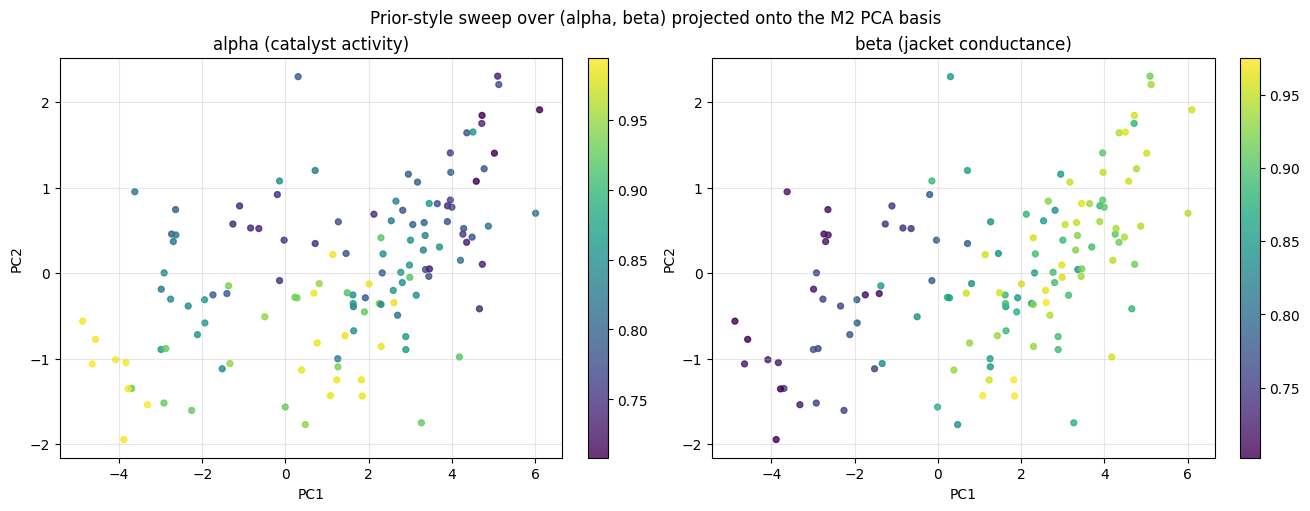

In [11]:
RUN_PRIOR_SWEEP = True
if RUN_PRIOR_SWEEP:
    from cstr_sbi.physics import (
        K0_NOMINAL, NOMINAL_CTRL, NOMINAL_INLET_CL, UA_NOMINAL,
    )
    from cstr_sbi.simulator import generate_replicates, warm_start_ic

    N_GRID = 32
    REPS = 4
    rng = np.random.default_rng(1)
    grid_alpha = rng.uniform(0.7, 1.0, size=N_GRID)
    grid_beta = rng.uniform(0.7, 1.0, size=N_GRID)

    all_S = []
    all_a = []
    all_b = []
    master_key = jax.random.PRNGKey(123)
    for i, (a, b) in enumerate(zip(grid_alpha, grid_beta)):
        params = jnp.array([UA_NOMINAL, K0_NOMINAL, float(a), float(b)])
        y0 = warm_start_ic(params, NOMINAL_INLET_CL, NOMINAL_CTRL)
        k = jax.random.fold_in(master_key, i)
        _, obs = generate_replicates(
            params, NOMINAL_INLET_CL, NOMINAL_CTRL, y0,
            n_replicates=REPS, master_key=k, t_window=60.0,
        )
        S_i = np.asarray(compute_summary_statistics_batch(obs, t))
        all_S.append(S_i)
        all_a.extend([float(a)] * REPS)
        all_b.extend([float(b)] * REPS)
    Z_prior = scaler.transform(np.vstack(all_S))
    Y_pca_prior = pca.transform(Z_prior)
    print(f"prior sweep: {Z_prior.shape[0]} windows over {N_GRID} (alpha,beta) draws")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for ax, c, title in [
        (axes[0], np.asarray(all_a), "alpha (catalyst activity)"),
        (axes[1], np.asarray(all_b), "beta (jacket conductance)"),
    ]:
        sc = ax.scatter(Y_pca_prior[:, 0], Y_pca_prior[:, 1], c=c, cmap="viridis", s=18, alpha=0.8)
        ax.set(xlabel="PC1", ylabel="PC2", title=title)
        ax.grid(alpha=0.3)
        fig.colorbar(sc, ax=ax)
    fig.suptitle("Prior-style sweep over (alpha, beta) projected onto the M2 PCA basis")
    fig.savefig(FIGS / "03_pca_prior_sweep.png", dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("prior sweep skipped")

## 9. M3 acceptance summary

* `cstr_sbi.summaries.compute_summary_statistics` produces a **29-D** feature
  vector: 20 per-channel base stats + 4 final-window means + 3 control
  aggregates + 2 physics-informed features (`UA_eff_proxy`, `k0_eff_proxy`)
  added after the M5 identifiability finding. NaN-tolerant; vmappable.
* Both PCA and t-SNE place the four closed-loop faults (Sc2, 3, 4, 5), the
  drift scenario (Sc7), and the two open-loop scenarios (Sc0, Sc6) in
  visibly distinguishable regions of the 2-D plane. Cross-validated LDA
  accuracy on the full 29-D feature vector is ≫ chance (1/8 = 12.5 %).
* The 2-feature `physics` subset (`UA_eff_proxy`, `k0_eff_proxy`) alone
  achieves ~98% LDA accuracy — directly encoding the identifiable products
  β·UA and α·k0.
* The top-10 mutual-information feature shortlist (29-D) is persisted to
  `data/03_feature_shortlist_29d.json`.

Next: **M4 — SBI training** (`04_sbi_training.ipynb`), using these features
and a 4-D `BoxUniform` prior on `[UA, k0, alpha, beta]`.

<!-- section10-summary-redesign -->
## 10. Can the summary statistics be improved? (fixed controller law, P1b — 2026-11-08)

**Why ask.** nb29 E2 shows the 29-D summaries already carry close to the information in the
raw trajectory (raw-trajectory Cramér–Rao bounds within ~10–20%). But at 5k simulations the
NPE posterior for α was several times wider than that bound and its full-set SBC failed. So
the headroom is mostly in how *learnable* the information is, not in how much there is.

**Candidates** (`scripts/summary_variants.py`, tested in `tests/test_summary_variants.py`):

| Set | Features | Idea |
|---|---|---|
| S0 | current 29 | reference (production) |
| S1 | S0 + 3 plug-in estimators | ln α̂ (component balance), ln β̂ (jacket balance), ln β̂ (reactor balance, independent of Qc): nearly linear in log θ, close to the Fearnhead–Prangle optimal summary E[θ|x] |
| S2 | S1 + 6 loop-dynamics + 4 detrended stds | lag-1 autocorrelations, T–Qc / T–Tc cross-correlations: β changes the plant gain, so the noise-driven closed-loop dynamics carry information the means do not |
| S3 | 19, compact | estimators, means, detrended stds, saturation, dynamics; drops noisy min/max/slope |
| S4 | 5, minimal | estimators + saturation fractions only |

**Protocol.** P1b, one set of simulations shared by all sets (features computed from the same
raw windows, so sets differ only by the features). Budgets 5k and 20k × 3 seeds, same NSF as
production. Test set: 1000 SBC draws + the scenario grid × 50 reps.

**Decision rule — fixed before results** (`scripts/nb03_summary_study.py`): at 20k, a candidate
replaces S0 only if it is calibrated (interior marginal KS p ≥ 0.01 for α and β, TARP KS p ≥ 0.01),
its RMSE is not worse, and either its efficiency (posterior sd / raw-trajectory CRB, Sc1–Sc4) is
≥ 10% better than S0's beyond 2 SE, or S0 fails calibration and the candidate does not lose
efficiency. Among winners the most efficient; a smaller set within 1 SE is preferred. No winner →
the paper keeps the 29-D summaries.


In [12]:
import json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N0"   # N0 run; default model is N3 since 2026-11-09
import importlib, system_I_config, ws_protocols, ws_eval, nb29_ws_study, nb03_summary_study, summary_variants as sv
for _m in (system_I_config, ws_protocols, ws_eval, nb29_ws_study, nb03_summary_study):
    importlib.reload(_m)
SS = nb03_summary_study
assert SS.SENSOR == "N0", SS.SENSOR
R10, FIGS10 = ROOT / "results", ROOT / "figures"
THREADS = 4
T0_10 = time.time()
print({k: len(v) for k, v in sv.SETS.items()})

{'S0_base29': 29, 'S1_base_est': 32, 'S2_base_est_dyn': 42, 'S3_compact': 19, 'S4_est_only': 5}


### 10.1 Simulate once (P1b), compute the union of all candidate features

In [13]:
SS.stage_sim()

training union (60000, 42) in 157s


### 10.2 Information content per set (Gaussian FIM, as nb29 E2)
Cramér–Rao sd per set at the nb29 points, next to nb29's raw-trajectory bound. A set whose
CRB is close to the raw bound loses little information; the NPE results below show whether
that information is also *learned*.

In [14]:
if not (R10 / "03s_fim.csv").exists():
    SS.stage_fim()
fim = pd.read_csv(R10 / "03s_fim.csv")
raw = pd.read_csv(R10 / "29fx_e2_fim.csv")
raw = raw[(raw.protocol == "P1b") & (raw.representation == "raw_traj_lwcov")][["point", "crb_sd_a", "crb_sd_b"]]
raw = raw.assign(set="raw trajectory (nb29)", n_features=480)
display(pd.concat([fim, raw]).pivot_table(index="set", columns="point", values=["crb_sd_a", "crb_sd_b"]).round(4))
display(fim.pivot_table(index="set", columns="point", values="corr_implied").round(3))

Sc1 done
Sc2 done
Sc3 done
Sc4 done


crb_sd_a                         crb_sd_b          \
point                      Sc1     Sc2     Sc3     Sc4      Sc1     Sc2   
set                                                                       
S0_base29               0.0014  0.0057  0.0009  0.0014   0.0360  0.0333   
S1_base_est             0.0014  0.0057  0.0009  0.0013   0.0359  0.0330   
S2_base_est_dyn         0.0014  0.0055  0.0009  0.0013   0.0358  0.0326   
S3_compact              0.0023  0.0069  0.0013  0.0047   0.0400  0.0356   
S4_est_only             0.0110  0.0086  0.0078  0.0090   0.0568  0.0378   
raw trajectory (nb29)   0.0012  0.0081  0.0008  0.0010   0.0330  0.0324   

                                       
point                     Sc3     Sc4  
set                                    
S0_base29              0.0367  0.0270  
S1_base_est            0.0367  0.0270  
S2_base_est_dyn        0.0365  0.0269  
S3_compact             0.0404  0.0303  
S4_est_only            0.0587  0.0464  
raw trajectory (nb29)  0.0348  0.0239

point,Sc1,Sc2,Sc3,Sc4
set,,,,
S0_base29,-0.074,0.438,-0.082,-0.015
S1_base_est,-0.075,0.444,-0.083,-0.014
S2_base_est_dyn,-0.076,0.434,-0.083,-0.009
S3_compact,-0.180,0.507,-0.157,-0.196
S4_est_only,0.639,0.570,0.665,0.558


### 10.3 Train NPE: 5 sets × 2 budgets × 3 seeds

In [15]:
SS.stage_train(THREADS)

/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [17, 25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


S0_base29 5000 0 18 s 69.0 epochs


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [17, 25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


S0_base29 20000 0 120 s 105.0 epochs
S0_base29 5000 1 28 s 103.0 epochs
S0_base29 20000 1 64 s 57.0 epochs
S0_base29 5000 2 18 s 68.0 epochs
S0_base29 20000 2 93 s 85.0 epochs
S1_base_est 5000 0 20 s 77.0 epochs
S1_base_est 20000 0 119 s 108.0 epochs
S1_base_est 5000 1 14 s 52.0 epochs
S1_base_est 20000 1 114 s 104.0 epochs
S1_base_est 5000 2 28 s 105.0 epochs
S1_base_est 20000 2 102 s 93.0 epochs
S2_base_est_dyn 5000 0 17 s 63.0 epochs
S2_base_est_dyn 20000 0 79 s 71.0 epochs
S2_base_est_dyn 5000 1 36 s 74.0 epochs
S2_base_est_dyn 20000 1 89 s 69.0 epochs
S2_base_est_dyn 5000 2 23 s 65.0 epochs
S2_base_est_dyn 20000 2 86 s 68.0 epochs


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [11] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


S3_compact 5000 0 28 s 94.0 epochs
S3_compact 20000 0 60 s 50.0 epochs
S3_compact 5000 1 13 s 42.0 epochs
S3_compact 20000 1 100 s 80.0 epochs
S3_compact 5000 2 37 s 127.0 epochs
S3_compact 20000 2 86 s 68.0 epochs


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [3] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


S4_est_only 5000 0 25 s 85.0 epochs
S4_est_only 20000 0 51 s 43.0 epochs
S4_est_only 5000 1 17 s 60.0 epochs
S4_est_only 20000 1 138 s 109.0 epochs
S4_est_only 5000 2 37 s 107.0 epochs
S4_est_only 20000 2 89 s 75.0 epochs


### 10.4 Evaluate on the shared held-out test set

In [16]:
SS.stage_eval()

S0_base29 5000 0 {'ks_p_a_interior': 0.0, 'ks_p_b_interior': 0.0, 'tarp_ks_p': 0.093, 'rmse_norm': 0.0353, 'macro_f1': 0.985}
S0_base29 5000 1 {'ks_p_a_interior': 0.1749, 'ks_p_b_interior': 0.0, 'tarp_ks_p': 0.0, 'rmse_norm': 0.0346, 'macro_f1': 0.985}
S0_base29 5000 2 {'ks_p_a_interior': 0.0, 'ks_p_b_interior': 0.851, 'tarp_ks_p': 0.093, 'rmse_norm': 0.0343, 'macro_f1': 0.98}
S0_base29 20000 0 {'ks_p_a_interior': 0.6739, 'ks_p_b_interior': 0.2648, 'tarp_ks_p': 0.1262, 'rmse_norm': 0.0314, 'macro_f1': 0.985}
S0_base29 20000 1 {'ks_p_a_interior': 0.0, 'ks_p_b_interior': 0.0467, 'tarp_ks_p': 0.0193, 'rmse_norm': 0.0318, 'macro_f1': 0.98}
S0_base29 20000 2 {'ks_p_a_interior': 0.0843, 'ks_p_b_interior': 0.447, 'tarp_ks_p': 0.4057, 'rmse_norm': 0.0317, 'macro_f1': 0.98}
S1_base_est 5000 0 {'ks_p_a_interior': 0.0, 'ks_p_b_interior': 0.9013, 'tarp_ks_p': 0.1685, 'rmse_norm': 0.0337, 'macro_f1': 0.9408}
S1_base_est 5000 1 {'ks_p_a_interior': 0.0, 'ks_p_b_interior': 0.0207, 'tarp_ks_p': 0.551, 

n_features  ks_p_a_interior  ks_p_b_interior  ks_p_a  \
set             budget                                                         
S0_base29       5000          29.0           0.0000           0.0000  0.0000   
                20000         29.0           0.0843           0.2648  0.2039   
S1_base_est     5000          32.0           0.0000           0.0207  0.0000   
                20000         32.0           0.0008           0.3569  0.0000   
S2_base_est_dyn 5000          42.0           0.0000           0.7773  0.0000   
                20000         42.0           0.0174           0.4500  0.0066   
S3_compact      5000          19.0           0.0000           0.3966  0.0000   
                20000         19.0           0.0093           0.0102  0.0006   
S4_est_only     5000           5.0           0.0004           0.0112  0.0006   
                20000          5.0           0.1286           0.0954  0.0541   

                        tarp_ks_p  cov90_a  cov90_b  rmse_norm  macro_f1  \
set             budget                                                     
S0_base29       5000       0.0930    0.914    0.865     0.0346    0.9850   
                20000      0.1262    0.911    0.872     0.0317    0.9800   
S1_base_est     5000       0.1685    0.894    0.862     0.0337    0.9734   
                20000      0.3227    0.881    0.872     0.0315    0.9850   
S2_base_est_dyn 5000       0.2520    0.882    0.858     0.0344    0.9800   
                20000      0.8109    0.913    0.878     0.0316    0.9800   
S3_compact      5000       0.2858    0.910    0.861     0.0348    0.9733   
                20000      0.1461    0.913    0.874     0.0337    0.9720   
S4_est_only     5000       0.0793    0.899    0.878     0.0425    0.8319   
                20000      0.3227    0.908    0.881     0.0409    0.8157   

                        leak_sbc_mean  
set             budget                 
S0_base29       5000           0.0202  
                20000          0.0090  
S1_base_est     5000           0.0202  
                20000          0.0093  
S2_base_est_dyn 5000           0.0222  
                20000          0.0111  
S3_compact      5000           0.0208  
                20000          0.0133  
S4_est_only     5000           0.0182  
                20000          0.0119

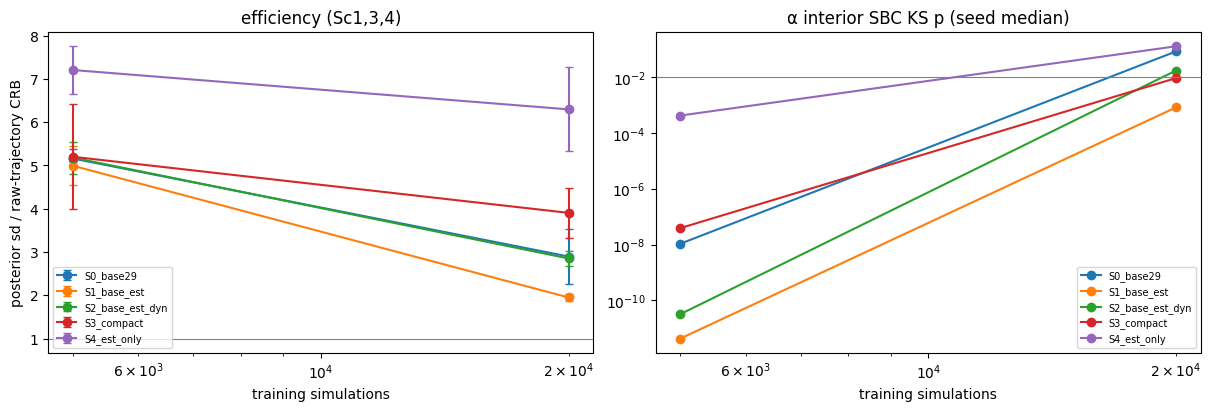

,n_features,eff,eff_a_Sc1,eff_a_Sc3,eff_a_Sc4,eff_b_Sc1,eff_b_Sc3,eff_b_Sc4
set,,,,,,,,
S0_base29,29.0,2.89,3.41,5.93,4.73,1.09,1.07,1.14
S1_base_est,32.0,1.95,2.55,3.08,2.85,1.07,1.04,1.11
S2_base_est_dyn,42.0,2.85,3.34,5.49,4.86,1.13,1.10,1.17
S3_compact,19.0,3.90,4.56,6.08,9.07,1.24,1.22,1.26
S4_est_only,5.0,6.30,10.13,12.12,10.16,1.73,1.76,1.88


In [17]:
m10 = pd.read_csv(R10 / "03s_metrics.csv")
cols = ["n_features", "ks_p_a_interior", "ks_p_b_interior", "ks_p_a", "tarp_ks_p", "cov90_a", "cov90_b",
        "rmse_norm", "macro_f1", "leak_sbc_mean"]
display(m10.groupby(["set", "budget"])[cols].median().round(4))
eff = pd.concat([SS.efficiency_table(N).assign(budget=N) for N in SS.BUDGETS])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for s, g in eff.groupby("set"):
    gg = g.groupby("budget").eff
    axes[0].errorbar(gg.mean().index, gg.mean(), yerr=gg.std(), marker="o", capsize=3, label=s)
axes[0].set_xscale("log"); axes[0].axhline(1, color="grey", lw=0.8)
axes[0].set_xlabel("training simulations"); axes[0].set_ylabel("posterior sd / raw-trajectory CRB")
axes[0].set_title("efficiency (Sc" + ",".join(p[2:] for p in eff.attrs.get("points", [])) + ")"); axes[0].legend(fontsize=7)
for s, g in m10.groupby("set"):
    gg = g.groupby("budget").ks_p_a_interior.median()
    axes[1].plot(gg.index, gg.values, "o-", label=s)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].axhline(0.01, color="grey", lw=0.8)
axes[1].set_xlabel("training simulations"); axes[1].set_title("α interior SBC KS p (seed median)"); axes[1].legend(fontsize=7)
fig.savefig(FIGS10 / "03s_summary_sets.png", dpi=150); plt.show()
display(eff[eff.budget == 20_000].groupby("set").mean(numeric_only=True).drop(columns=["seed", "budget"]).round(2))

### 10.5 Decision (pre-set rule)

In [18]:
res10 = SS.stage_decide()
print("CHOICE:", res10["choice"], "| winners:", res10["winners"])
print(f"section 10 wall time {(time.time() - T0_10) / 60:.1f} min")

                 n_features  ks_a_int  ks_b_int  tarp_ks    rmse  rmse_se      f1  cov90_a  cov90_b     eff  eff_se  calib_ok
set                                                                                                                          
S0_base29                29    0.0843    0.2648   0.1262  0.0316   0.0001  0.9816   0.9117   0.8730  2.8948  0.3667      True
S1_base_est              32    0.0008    0.3569   0.3227  0.0315   0.0000  0.9816   0.8873   0.8677  1.9486  0.0482     False
S2_base_est_dyn          42    0.0174    0.4500   0.8109  0.0316   0.0001  0.9800   0.9127   0.8800  2.8504  0.0953      True
S3_compact               19    0.0093    0.0102   0.1461  0.0335   0.0002  0.9707   0.9157   0.8770  3.9042  0.3344     False
S4_est_only               5    0.1286    0.0954   0.3227  0.0412   0.0004  0.8318   0.9097   0.8867  6.2966  0.5597      True
winners: [] | CHOICE: S0_base29
CHOICE: S0_base29 | winners: []
section 10 wall time 42.1 min


### 10.6 What follows from the decision
- **S0 kept:** the paper's summaries stand; report this section as evidence that the 29-D set is
  close to sufficient and that the remaining gap is estimator learning (budget, nb31).
- **A candidate wins:** promote it into `cstr_sbi.summaries` as a new, versioned feature set
  (keep the 29-D function for traceability), then nb31's bank and test set must be recomputed
  with it before the budget study is run. nb29's protocol conclusion is unaffected (protocols
  were compared with the same summaries on both sides).

<!-- section10-summary-redesign-N3 -->
## 10. Can the summary statistics be improved? (fixed controller law, P2 — 2026-11-08)

**Why ask.** nb29 E2 shows the 29-D summaries already carry close to the information in the
raw trajectory (raw-trajectory Cramér–Rao bounds within ~10–20%). But at 5k simulations the
NPE posterior for α was several times wider than that bound and its full-set SBC failed. So
the headroom is mostly in how *learnable* the information is, not in how much there is.

**Candidates** (`scripts/summary_variants.py`, tested in `tests/test_summary_variants.py`):

| Set | Features | Idea |
|---|---|---|
| S0 | current 29 | reference (production) |
| S1 | S0 + 3 plug-in estimators | ln α̂ (component balance), ln β̂ (jacket balance), ln β̂ (reactor balance, independent of Qc): nearly linear in log θ, close to the Fearnhead–Prangle optimal summary E[θ|x] |
| S2 | S1 + 6 loop-dynamics + 4 detrended stds | lag-1 autocorrelations, T–Qc / T–Tc cross-correlations: β changes the plant gain, so the noise-driven closed-loop dynamics carry information the means do not |
| S3 | 19, compact | estimators, means, detrended stds, saturation, dynamics; drops noisy min/max/slope |
| S4 | 5, minimal | estimators + saturation fractions only |

**Protocol.** P2, one set of simulations shared by all sets (features computed from the same
raw windows, so sets differ only by the features). Budgets 5k and 20k × 3 seeds, same NSF as
production. Test set: 1000 SBC draws + the scenario grid × 50 reps.

**Decision rule — fixed before results** (`scripts/nb03_summary_study.py`): at 20k, a candidate
replaces S0 only if it is calibrated (interior marginal KS p ≥ 0.01 for α and β, TARP KS p ≥ 0.01),
its RMSE is not worse, and either its efficiency (posterior sd / raw-trajectory CRB, Sc1–Sc4) is
≥ 10% better than S0's beyond 2 SE, or S0 fails calibration and the candidate does not lose
efficiency. Among winners the most efficient; a smaller set within 1 SE is preferred. No winner →
the paper keeps the 29-D summaries.

> **Sensor model: N3** (N3: sigma_C=0.01 mol/L, sigma_T=0.2 K, sigma_Tc=0.2 K, sigma_Qc=2.0 L/min). Re-run of section 10 under the production sensor model
> adopted on 2026-11-09 (notebook 33); section 10 above is the N0 run. Warm-start protocol: the one
> nb29 selects for this sensor model (under N3 the pre-set rule chose P2, adopted by the user on
> 2026-11-09; under N0 it was P1b). With realistic sensors
> the information moves between channels (C becomes ~30× less informative about α, T ~2×
> more informative about β), so the comparison of summary sets must be repeated. Same rule,
> same seeds; outputs carry the prefix `03s_N3_`.
> **If a candidate set wins, STOP**: promoting it into `cstr_sbi.summaries` (and rebuilding
> nb31's bank) is a user decision.


In [1]:
import json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_protocols, ws_eval, system_I_config, nb29_ws_study, nb03_summary_study, summary_variants as sv
for _m in (system_I_config, ws_protocols, ws_eval, nb29_ws_study, nb03_summary_study):
    importlib.reload(_m)
SS = nb03_summary_study
assert SS.SENSOR == "N3", SS.SENSOR
R10, FIGS10 = ROOT / "results", ROOT / "figures"
THREADS = 4
T0_10 = time.time()
print({k: len(v) for k, v in sv.SETS.items()})

{'S0_base29': 29, 'S1_base_est': 32, 'S2_base_est_dyn': 42, 'S3_compact': 19, 'S4_est_only': 5}


### 10b.1 Simulate once (P2), compute the union of all candidate features

In [2]:
SS.stage_sim()

training union (60000, 42) in 262s


### 10b.2 Information content per set (Gaussian FIM, as nb29 E2)
Cramér–Rao sd per set at the nb29 points, next to nb29's raw-trajectory bound. A set whose
CRB is close to the raw bound loses little information; the NPE results below show whether
that information is also *learned*.

In [3]:
if not (R10 / f"{SS.TAG}_fim.csv").exists():
    SS.stage_fim()
fim = pd.read_csv(R10 / f"{SS.TAG}_fim.csv")
raw = pd.read_csv(R10 / f"{SS.E2_TAG}_e2_fim.csv")
raw = raw[(raw.protocol == SS.PROTOCOL) & (raw.representation == "raw_traj_lwcov")][["point", "crb_sd_a", "crb_sd_b"]]
raw = raw.assign(set="raw trajectory (nb29)", n_features=480)
display(pd.concat([fim, raw]).pivot_table(index="set", columns="point", values=["crb_sd_a", "crb_sd_b"]).round(4))
display(fim.pivot_table(index="set", columns="point", values="corr_implied").round(3))

Sc1 done


Sc2 done


Sc3 done


Sc4 done


crb_sd_a                         crb_sd_b          \
point                      Sc1     Sc2     Sc3     Sc4      Sc1     Sc2   
set                                                                       
S0_base29               0.0536  0.0556  0.0267  0.0388   0.0156  0.0236   
S1_base_est             0.0535  0.0551  0.0266  0.0386   0.0142  0.0236   
S2_base_est_dyn         0.0534  0.0549  0.0266  0.0385   0.0141  0.0235   
S3_compact              0.0540  0.0558  0.0269  0.0394   0.0267  0.0242   
S4_est_only             0.0547  0.0562  0.0272  0.0397   0.0366  0.0243   
raw trajectory (nb29)   0.0454  0.0472  0.0227  0.0326   0.0310  0.0196   

                                       
point                     Sc3     Sc4  
set                                    
S0_base29              0.0161  0.0166  
S1_base_est            0.0150  0.0150  
S2_base_est_dyn        0.0149  0.0148  
S3_compact             0.0260  0.0253  
S4_est_only            0.0371  0.0323  
raw trajectory (nb29)  0.0324  0.0222

point,Sc1,Sc2,Sc3,Sc4
set,,,,
S0_base29,0.025,0.113,0.027,0.099
S1_base_est,0.045,0.108,0.048,0.084
S2_base_est_dyn,0.051,0.109,0.051,0.085
S3_compact,0.118,0.108,0.106,0.122
S4_est_only,0.146,0.106,0.135,0.127


### 10b.3 Train NPE: 5 sets × 2 budgets × 3 seeds

In [4]:
SS.stage_train(THREADS)

/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [12, 17, 25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


S0_base29 5000 0 15 s 60.0 epochs


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [12, 17, 25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


S0_base29 20000 0 69 s 71.0 epochs


S0_base29 5000 1 17 s 70.0 epochs


S0_base29 20000 1 74 s 76.0 epochs


... (24 outputs left out)

S4_est_only 5000 1 13 s 58.0 epochs


S4_est_only 20000 1 84 s 88.0 epochs


S4_est_only 5000 2 11 s 47.0 epochs


S4_est_only 20000 2 73 s 76.0 epochs


### 10b.4 Evaluate on the shared held-out test set

In [5]:
SS.stage_eval()

S0_base29 5000 0 {'ks_p_a_interior': 0.018, 'ks_p_b_interior': 0.0001, 'tarp_ks_p': 0.2213, 'rmse_norm': 0.0407, 'macro_f1': 0.8328}


S0_base29 5000 1 {'ks_p_a_interior': 0.2483, 'ks_p_b_interior': 0.0012, 'tarp_ks_p': 0.0001, 'rmse_norm': 0.0412, 'macro_f1': 0.8591}


S0_base29 5000 2 {'ks_p_a_interior': 0.0039, 'ks_p_b_interior': 0.0001, 'tarp_ks_p': 0.0003, 'rmse_norm': 0.0411, 'macro_f1': 0.9064}


S0_base29 20000 0 {'ks_p_a_interior': 0.2277, 'ks_p_b_interior': 0.3527, 'tarp_ks_p': 0.0481, 'rmse_norm': 0.0384, 'macro_f1': 0.8713}


S0_base29 20000 1 {'ks_p_a_interior': 0.0002, 'ks_p_b_interior': 0.0007, 'tarp_ks_p': 0.0045, 'rmse_norm': 0.0388, 'macro_f1': 0.844}


S0_base29 20000 2 {'ks_p_a_interior': 0.1282, 'ks_p_b_interior': 0.111, 'tarp_ks_p': 0.0056, 'rmse_norm': 0.0383, 'macro_f1': 0.878}


... (20 outputs left out)

S4_est_only 5000 2 {'ks_p_a_interior': 0.0639, 'ks_p_b_interior': 0.479, 'tarp_ks_p': 0.6566, 'rmse_norm': 0.0416, 'macro_f1': 0.8241}


S4_est_only 20000 0 {'ks_p_a_interior': 0.2323, 'ks_p_b_interior': 0.2465, 'tarp_ks_p': 0.2213, 'rmse_norm': 0.0408, 'macro_f1': 0.825}


S4_est_only 20000 1 {'ks_p_a_interior': 0.0045, 'ks_p_b_interior': 0.145, 'tarp_ks_p': 0.4517, 'rmse_norm': 0.0412, 'macro_f1': 0.8084}


S4_est_only 20000 2 {'ks_p_a_interior': 0.8707, 'ks_p_b_interior': 0.2748, 'tarp_ks_p': 0.8109, 'rmse_norm': 0.041, 'macro_f1': 0.8153}


n_features  ks_p_a_interior  ks_p_b_interior  ks_p_a  \
set             budget                                                         
S0_base29       5000          29.0           0.0180           0.0001  0.0386   
                20000         29.0           0.1282           0.1110  0.0689   
S1_base_est     5000          32.0           0.0569           0.0190  0.0071   
                20000         32.0           0.6517           0.7619  0.3564   
S2_base_est_dyn 5000          42.0           0.1372           0.0001  0.0019   
                20000         42.0           0.0025           0.0274  0.0019   
S3_compact      5000          19.0           0.0024           0.0534  0.0000   
                20000         19.0           0.0523           0.4907  0.0261   
S4_est_only     5000           5.0           0.0639           0.4790  0.0303   
                20000          5.0           0.2323           0.2465  0.1965   

                        tarp_ks_p  cov90_a  cov90_b  rmse_norm  macro_f1  \
set             budget                                                     
S0_base29       5000       0.0003    0.853    0.849     0.0411    0.8591   
                20000      0.0056    0.883    0.867     0.0384    0.8713   
S1_base_est     5000       0.0106    0.883    0.867     0.0382    0.8451   
                20000      0.0481    0.882    0.882     0.0369    0.8783   
S2_base_est_dyn 5000       0.0159    0.866    0.880     0.0381    0.8709   
                20000      0.0338    0.886    0.880     0.0373    0.8451   
S3_compact      5000       0.1461    0.875    0.885     0.0407    0.8260   
                20000      0.0793    0.885    0.863     0.0390    0.8309   
S4_est_only     5000       0.5003    0.886    0.898     0.0423    0.8123   
                20000      0.4517    0.898    0.892     0.0410    0.8153   

                        leak_sbc_mean  
set             budget                 
S0_base29       5000           0.0174  
                20000          0.0078  
S1_base_est     5000           0.0219  
                20000          0.0096  
S2_base_est_dyn 5000           0.0178  
                20000          0.0144  
S3_compact      5000           0.0176  
                20000          0.0118  
S4_est_only     5000           0.0214  
                20000          0.0083

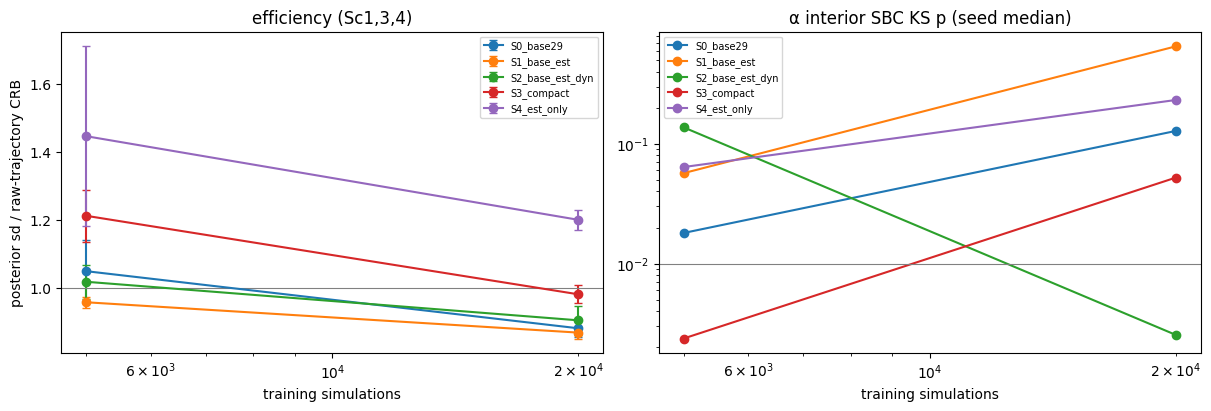

,n_features,eff,eff_a_Sc1,eff_a_Sc3,eff_a_Sc4,eff_b_Sc1,eff_b_Sc3,eff_b_Sc4
set,,,,,,,,
S0_base29,29.0,0.88,1.19,1.16,1.23,0.50,0.50,0.69
S1_base_est,32.0,0.87,1.18,1.21,1.24,0.47,0.48,0.62
S2_base_est_dyn,42.0,0.90,1.24,1.24,1.34,0.48,0.49,0.64
S3_compact,19.0,0.98,1.14,1.15,1.21,0.73,0.67,0.97
S4_est_only,5.0,1.20,1.20,1.22,1.27,1.15,1.12,1.23


In [6]:
m10 = pd.read_csv(R10 / f"{SS.TAG}_metrics.csv")
cols = ["n_features", "ks_p_a_interior", "ks_p_b_interior", "ks_p_a", "tarp_ks_p", "cov90_a", "cov90_b",
        "rmse_norm", "macro_f1", "leak_sbc_mean"]
display(m10.groupby(["set", "budget"])[cols].median().round(4))
eff = pd.concat([SS.efficiency_table(N).assign(budget=N) for N in SS.BUDGETS])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for s, g in eff.groupby("set"):
    gg = g.groupby("budget").eff
    axes[0].errorbar(gg.mean().index, gg.mean(), yerr=gg.std(), marker="o", capsize=3, label=s)
axes[0].set_xscale("log"); axes[0].axhline(1, color="grey", lw=0.8)
axes[0].set_xlabel("training simulations"); axes[0].set_ylabel("posterior sd / raw-trajectory CRB")
axes[0].set_title("efficiency (Sc" + ",".join(p[2:] for p in eff.attrs.get("points", [])) + ")"); axes[0].legend(fontsize=7)
for s, g in m10.groupby("set"):
    gg = g.groupby("budget").ks_p_a_interior.median()
    axes[1].plot(gg.index, gg.values, "o-", label=s)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].axhline(0.01, color="grey", lw=0.8)
axes[1].set_xlabel("training simulations"); axes[1].set_title("α interior SBC KS p (seed median)"); axes[1].legend(fontsize=7)
fig.savefig(FIGS10 / f"{SS.TAG}_summary_sets.png", dpi=150); plt.show()
display(eff[eff.budget == 20_000].groupby("set").mean(numeric_only=True).drop(columns=["seed", "budget"]).round(2))

### 10b.5 Decision (pre-set rule)

In [7]:
res10 = SS.stage_decide()
print("CHOICE:", res10["choice"], "| winners:", res10["winners"])
print(f"section 10 wall time {(time.time() - T0_10) / 60:.1f} min")
if res10["choice"] != "S0_base29":
    raise RuntimeError("STOP: a candidate summary set wins under this sensor model -- "
                       "promoting it is a user decision (re-run plan, Phase 1b)")

                 n_features  ks_a_int  ks_b_int  tarp_ks    rmse  rmse_se      f1  cov90_a  cov90_b     eff  eff_se  calib_ok
set                                                                                                                          
S0_base29                29    0.1282    0.1110   0.0056  0.0385   0.0002  0.8644   0.8770   0.8603  0.8800  0.0141     False
S1_base_est              32    0.6517    0.7619   0.0481  0.0370   0.0001  0.8670   0.8887   0.8803  0.8672  0.0100      True
S2_base_est_dyn          42    0.0025    0.0274   0.0338  0.0372   0.0001  0.8436   0.8920   0.8830  0.9035  0.0251     False
S3_compact               19    0.0523    0.4907   0.0793  0.0391   0.0001  0.8414   0.8813   0.8717  0.9802  0.0155      True
S4_est_only               5    0.2323    0.2465   0.4517  0.0410   0.0001  0.8162   0.8990   0.8947  1.2000  0.0165      True
winners: ['S1_base_est'] | CHOICE: S1_base_est
CHOICE: S1_base_est | winners: ['S1_base_est']
section 10 wall time 32.

RuntimeError: STOP: a candidate summary set wins under this sensor model -- promoting it is a user decision (re-run plan, Phase 1b)

### 10b.6 What follows from the decision
- **S0 kept:** the paper's summaries stand; report this section as evidence that the 29-D set is
  close to sufficient and that the remaining gap is estimator learning (budget, nb31).
- **A candidate wins:** promote it into `cstr_sbi.summaries` as a new, versioned feature set
  (keep the 29-D function for traceability), then nb31's bank and test set must be recomputed
  with it before the budget study is run. nb29's protocol conclusion is unaffected (protocols
  were compared with the same summaries on both sides).

**Outcome (2026-11-09):** a candidate won (S1_base_est). The decision cell stopped the pipeline as designed; the user adopted S1 as the N3 production summary set (`results/03s_N3_decision_review.json`), with S0 reported side by side. N0 production stays S0.

### 10b.7 Interpretation (N3 + P2) — written 2026-11-09

**Result.** Under realistic sensors the pre-set rule selects **S1** (the 29 summaries plus three physics-based plug-in estimators, 32 features) over S0 (the 29 summaries). S1 restores joint calibration at equal efficiency: at the 20k budget (3-seed means) S0 fails the TARP gate (KS p 0.0056, gate 0.01) while S1 passes it (0.048), the interior marginal calibration improves (α 0.128 → 0.652, β 0.111 → 0.762), RMSE falls from 0.0385 ± 0.0002 to 0.0370 ± 0.0001, and efficiency, the posterior sd divided by the raw-trajectory Cramér–Rao sd, is the same within its error (0.880 ± 0.014 against 0.867 ± 0.010; the difference of 0.013 is smaller than the combined standard error, 0.017). The direction is the same at 5k (TARP KS p 0.0003 → 0.0106, interior β KS p 0.0001 → 0.019). **The decision is marginal**: it is made by a gate of 0.01 on a TARP p-value of 0.0056 against 0.048 with three seeds, so the user adopted S1 following the rule and S0 is reported next to it, as P1b is next to P2 for the warm start.

| set (features) | interior KS p α / β | TARP KS p | RMSE | macro-F1 | efficiency | β bound at Sc1 / Sc3 / Sc4 |
|---|---|---|---|---|---|---|
| S0 (29) | 0.128 / 0.111 | 0.0056 | 0.0385 | 0.864 | 0.880 | 0.0156 / 0.0161 / 0.0166 |
| **S1 (32)** | **0.652 / 0.762** | **0.048** | **0.0370** | **0.867** | **0.867** | 0.0142 / 0.0150 / 0.0150 |
| S2 (42) | 0.0025 / 0.027 | 0.034 | 0.0372 | 0.844 | 0.904 | 0.0141 / 0.0149 / 0.0148 |
| S3 (19) | 0.052 / 0.491 | 0.079 | 0.0391 | 0.841 | 0.980 | 0.0267 / 0.0260 / 0.0253 |
| S4 (5) | 0.232 / 0.247 | 0.452 | 0.0410 | 0.816 | 1.200 | 0.0366 / 0.0371 / 0.0323 |

**What the information tables say (10b.2).** The three plug-in estimators tighten the Cramér–Rao bound for β by 7–10% and leave the bound for α unchanged (0.0535 against 0.0536 at Sc1); adding loop-dynamics features and detrended standard deviations (S2) gains nothing further (β 0.0141 against 0.0142) and costs calibration (interior α KS p 0.0025). The five-feature set S4 shows where the information sits: α is carried almost entirely by the estimator (bound 0.0547 against 0.0536), while β needs the other features (0.0366, 2.3× looser). The raw-trajectory bound is 12–15% tighter than the summary bound for α (0.045 against 0.054 at Sc1); for β it is *looser* (0.031), a Ledoit–Wolf shrinkage artefact, so the efficiency below 1 for β (0.47–0.69) is not evidence that the posterior beats the information limit and the comparison between sets, which the rule uses, is the valid one. For α the posterior sd is 1.16–1.24 times the raw bound at 20k, i.e. there is still an estimator-learning gap, which notebook 31 addresses through the budget. (The "Sc2" column of the information table is the old β = 0.70 point and is not used in the efficiency.)

**What this means for the paper, toward the storyline.** (1) *The "reliable" half:* the 29 hand-crafted summaries are close to sufficient: no candidate set tightens the α bound, the best candidates tighten the β bound by at most 10%, and the extra physics-based estimators are what improves *joint calibration* (SBC and TARP) at equal efficiency; this belongs with the practitioner checklist item "check joint calibration, and precision against the information limit". (2) *A source of silent failure to disclose:* the plug-in estimators encode the **nominal inlet conditions** (Ci, Ti, Tci, Q, V) and the nominal kinetic constants explicitly, so a wrong feed temperature enters S1 directly through the estimators. Whether S1 is more or less sensitive to this than S0 is exactly what the inlet-uncertainty study (R2, notebook 34) must show, and it will run both sets. (3) The result depends on the sensor model (under N0 no candidate won): it is another case where a design choice that looks inconsequential with idealised sensors becomes relevant with realistic ones.
